In [5]:
import sys

print("Python version:")
print(sys.version)

print("\nPython executable:")
print(sys.executable)

Python version:
3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]

Python executable:
c:\Research\Cancer_Gene_XAI\.venv\Scripts\python.exe


In [6]:
import pandas as pd

# Load cancer labels
labels_path = "../data/raw/cancer_labels.tsv"

labels = pd.read_csv(
    labels_path,
    sep="\t"
)

print("Dataset shape:", labels.shape)

print("\nColumns:")
print(labels.columns.tolist())

print("\nFirst 5 rows:")
display(labels.head())

Dataset shape: (12591, 34)

Columns:
['sample', '_PATIENT', 'cancer type abbreviation', 'age_at_initial_pathologic_diagnosis', 'gender', 'race', 'ajcc_pathologic_tumor_stage', 'clinical_stage', 'histological_type', 'histological_grade', 'initial_pathologic_dx_year', 'menopause_status', 'birth_days_to', 'vital_status', 'tumor_status', 'last_contact_days_to', 'death_days_to', 'cause_of_death', 'new_tumor_event_type', 'new_tumor_event_site', 'new_tumor_event_site_other', 'new_tumor_event_dx_days_to', 'treatment_outcome_first_course', 'margin_status', 'residual_tumor', 'OS', 'OS.time', 'DSS', 'DSS.time', 'DFI', 'DFI.time', 'PFI', 'PFI.time', 'Redaction']

First 5 rows:


,sample,_PATIENT,cancer type abbreviation,age_at_initial_pathologic_diagnosis,gender,race,ajcc_pathologic_tumor_stage,clinical_stage,histological_type,histological_grade,...,residual_tumor,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
0,TCGA-OR-A5J1-01,TCGA-OR-A5J1,ACC,58.0,MALE,WHITE,Stage II,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,1355.0,1.0,1355.0,1.0,754.0,1.0,754.0,NaN
1,TCGA-OR-A5J2-01,TCGA-OR-A5J2,ACC,44.0,FEMALE,WHITE,Stage IV,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,1677.0,1.0,1677.0,NaN,NaN,1.0,289.0,NaN
2,TCGA-OR-A5J3-01,TCGA-OR-A5J3,ACC,23.0,FEMALE,WHITE,Stage III,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,0.0,2091.0,0.0,2091.0,1.0,53.0,1.0,53.0,NaN
3,TCGA-OR-A5J4-01,TCGA-OR-A5J4,ACC,23.0,FEMALE,WHITE,Stage IV,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,423.0,1.0,423.0,NaN,NaN,1.0,126.0,NaN
4,TCGA-OR-A5J5-01,TCGA-OR-A5J5,ACC,30.0,MALE,WHITE,Stage III,NaN,Adrenocortical carcinoma- Usual Type,NaN,...,NaN,1.0,365.0,1.0,365.0,NaN,NaN,1.0,50.0,NaN


In [7]:
# Cancer type distribution

cancer_counts = labels["cancer type abbreviation"].value_counts()

print("Number of cancer types:", cancer_counts.shape[0])
print("\nSamples per cancer type:")
display(cancer_counts)

Number of cancer types: 33

Samples per cancer type:


cancer type abbreviation
BRCA    1236
KIRC     944
LUAD     641
LUSC     623
HNSC     604
OV       604
GBM      602
UCEC     583
THCA     580
PRAD     566
COAD     545
LGG      529
STAD     511
SKCM     479
LIHC     438
BLCA     436
KIRP     352
CESC     312
SARC     271
ESCA     204
LAML     200
PAAD     196
PCPG     187
READ     183
TGCT     139
THYM     126
ACC       92
KICH      91
MESO      87
UVM       80
UCS       57
DLBC      48
CHOL      45
Name: count, dtype: int64

In [8]:
import gzip

expression_path = "../data/raw/gene_expression.xena.gz"

with gzip.open(expression_path, "rt") as f:
    header = f.readline().rstrip("\n").split("\t")

expression_sample_ids = header[1:]

print("Number of expression samples:", len(expression_sample_ids))
print("\nFirst 10 expression sample IDs:")
print(expression_sample_ids[:10])

Number of expression samples: 11069

First 10 expression sample IDs:
['TCGA-OR-A5J1-01', 'TCGA-OR-A5J2-01', 'TCGA-OR-A5J3-01', 'TCGA-OR-A5J5-01', 'TCGA-OR-A5J6-01', 'TCGA-OR-A5J7-01', 'TCGA-OR-A5J8-01', 'TCGA-OR-A5J9-01', 'TCGA-OR-A5JA-01', 'TCGA-OR-A5JB-01']


In [9]:
# Compare sample IDs between expression data and clinical labels

label_sample_ids = set(labels["sample"].dropna())

expression_sample_ids_set = set(expression_sample_ids)

common_samples = expression_sample_ids_set.intersection(label_sample_ids)

print("Expression samples:", len(expression_sample_ids_set))
print("Label samples:", len(label_sample_ids))
print("Common samples:", len(common_samples))

print("\nExpression samples without labels:",
      len(expression_sample_ids_set - label_sample_ids))

print("Labels without expression data:",
      len(label_sample_ids - expression_sample_ids_set))

Expression samples: 11060
Label samples: 12591
Common samples: 11014

Expression samples without labels: 46
Labels without expression data: 1577


In [10]:
# Find expression samples that do not have a cancer label

unmatched_expression = sorted(
    expression_sample_ids_set - label_sample_ids
)

print("Number of unmatched expression samples:", len(unmatched_expression))

print("\nUnmatched samples:")
for sample in unmatched_expression:
    print(sample)

Number of unmatched expression samples: 46

Unmatched samples:
TCGA-06-0675-11
TCGA-06-0678-11
TCGA-06-0680-11
TCGA-06-0681-11
TCGA-06-AABW-11
TCGA-28-2510-01
TCGA-2G-AAKO-01
TCGA-2G-AAKO-05
TCGA-2G-AALF-01
TCGA-2G-AALG-01
TCGA-2G-AALN-01
TCGA-2G-AALO-01
TCGA-2G-AALQ-01
TCGA-2G-AALR-01
TCGA-2G-AALS-01
TCGA-2G-AALT-01
TCGA-2G-AALW-01
TCGA-2G-AALX-01
TCGA-2G-AALY-01
TCGA-2G-AALZ-01
TCGA-2G-AAM2-01
TCGA-2G-AAM3-01
TCGA-2G-AAM4-01
TCGA-33-4579-01
TCGA-5M-AAT5-01
TCGA-5M-AATA-01
TCGA-BH-A0B2-01
TCGA-BH-A0B2-11
TCGA-E2-A1IP-01
TCGA-F4-6857-01
TCGA-F5-6810-01
TCGA-FL-A1YF-11
TCGA-FL-A1YG-11
TCGA-FL-A1YH-11
TCGA-FL-A1YI-11
TCGA-FL-A1YL-11
TCGA-FL-A1YM-11
TCGA-FL-A1YN-11
TCGA-FL-A1YQ-11
TCGA-FL-A1YT-11
TCGA-FL-A1YU-11
TCGA-FL-A1YV-11
TCGA-FL-A3WE-11
TCGA-GN-A261-06
TCGA-PN-A8M9-01
TCGA-R8-A6YH-01


In [11]:
# Keep only samples that exist in both datasets

matched_samples = sorted(
    expression_sample_ids_set.intersection(label_sample_ids)
)

# Create sample -> cancer type mapping
sample_labels = labels[
    labels["sample"].isin(matched_samples)
][
    ["sample", "cancer type abbreviation"]
].copy()

# Remove any duplicate sample IDs, if present
sample_labels = sample_labels.drop_duplicates(subset="sample")

print("Final matched samples:", len(sample_labels))

print("\nMissing cancer labels:")
print(sample_labels["cancer type abbreviation"].isna().sum())

print("\nNumber of cancer types:")
print(sample_labels["cancer type abbreviation"].nunique())

print("\nFinal label distribution:")
display(
    sample_labels["cancer type abbreviation"]
    .value_counts()
)

Final matched samples: 11014

Missing cancer labels:
0

Number of cancer types:
33

Final label distribution:


cancer type abbreviation
BRCA    1215
KIRC     606
LUAD     576
THCA     572
HNSC     566
UCEC     555
LUSC     552
PRAD     550
LGG      529
COAD     492
SKCM     473
STAD     450
BLCA     427
LIHC     423
KIRP     323
CESC     309
OV       308
SARC     265
ESCA     196
PCPG     187
PAAD     183
LAML     173
READ     170
GBM      166
TGCT     139
THYM     122
KICH      91
MESO      87
UVM       80
ACC       79
UCS       57
DLBC      48
CHOL      45
Name: count, dtype: int64

In [12]:
import pandas as pd

expression_path = "../data/raw/gene_expression.xena.gz"

expression_preview = pd.read_csv(
    expression_path,
    sep="\t",
    compression="gzip",
    nrows=5
)

print("Preview shape:", expression_preview.shape)

print("\nFirst 10 columns:")
print(expression_preview.columns[:10].tolist())

print("\nFirst 5 rows:")
display(expression_preview.head())

Preview shape: (5, 11070)

First 10 columns:
['sample', 'TCGA-OR-A5J1-01', 'TCGA-OR-A5J2-01', 'TCGA-OR-A5J3-01', 'TCGA-OR-A5J5-01', 'TCGA-OR-A5J6-01', 'TCGA-OR-A5J7-01', 'TCGA-OR-A5J8-01', 'TCGA-OR-A5J9-01', 'TCGA-OR-A5JA-01']

First 5 rows:


,sample,TCGA-OR-A5J1-01,TCGA-OR-A5J2-01,TCGA-OR-A5J3-01,TCGA-OR-A5J5-01,TCGA-OR-A5J6-01,TCGA-OR-A5J7-01,TCGA-OR-A5J8-01,TCGA-OR-A5J9-01,TCGA-OR-A5JA-01,...,TCGA-CG-4449-01,TCGA-CG-4462-01,TCGA-CG-4465-01,TCGA-CG-4466-01,TCGA-CG-4469-01,TCGA-CG-4472-01,TCGA-CG-4474-01,TCGA-CG-4475-01,TCGA-CG-4476-01,TCGA-CG-4477-01
0,100130426,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,100133144,2.09,1.88,1.45,0.00,0.00,1.12,1.29,0.00,2.45,...,2.42,2.74,2.64,3.99,4.40,3.00,4.27,3.71,4.29,4.24
2,100134869,2.30,3.32,2.92,1.35,2.45,2.82,1.72,1.24,2.60,...,1.87,2.12,1.78,2.60,3.66,3.87,3.07,3.65,3.64,3.99
3,10357,7.23,6.36,6.45,5.78,6.09,6.71,6.58,6.31,6.13,...,9.31,8.20,9.43,9.14,10.02,9.32,9.54,8.99,9.48,9.46
4,10431,10.99,10.35,10.04,11.20,10.30,10.87,9.96,10.78,10.25,...,10.23,9.33,10.21,9.38,9.34,10.34,10.17,10.43,9.93,10.76


In [13]:
# Check the gene-ID column and make sure each gene appears only once.

print("Gene ID column:", expression_preview.columns[0])

gene_ids = expression_preview.iloc[:, 0]

print("Unique gene IDs in preview:", gene_ids.nunique())
print("Total rows in preview:", len(gene_ids))

Gene ID column: sample
Unique gene IDs in preview: 5
Total rows in preview: 5


In [14]:
# Verify the exact number of columns and inspect the first gene identifiers.

import gzip

with gzip.open(expression_path, "rt") as f:
    header_line = f.readline().rstrip("\n").split("\t")
    first_data_lines = [f.readline().rstrip("\n").split("\t") for _ in range(5)]

print("Total columns in raw header:", len(header_line))
print("First column name:", header_line[0])
print("Number of sample columns:", len(header_line) - 1)

print("\nFirst 10 sample IDs:")
print(header_line[1:11])

print("\nFirst 5 gene IDs:")
for row in first_data_lines:
    print(row[0])

Total columns in raw header: 11070
First column name: sample
Number of sample columns: 11069

First 10 sample IDs:
['TCGA-OR-A5J1-01', 'TCGA-OR-A5J2-01', 'TCGA-OR-A5J3-01', 'TCGA-OR-A5J5-01', 'TCGA-OR-A5J6-01', 'TCGA-OR-A5J7-01', 'TCGA-OR-A5J8-01', 'TCGA-OR-A5J9-01', 'TCGA-OR-A5JA-01', 'TCGA-OR-A5JB-01']

First 5 gene IDs:
100130426
100133144
100134869
10357
10431


In [15]:
# Recheck expression sample IDs and identify any duplicate sample names.

with gzip.open(expression_path, "rt") as f:
    header = f.readline().rstrip("\n").split("\t")

raw_expression_ids = header[1:]

print("Raw expression samples:", len(raw_expression_ids))
print("Unique expression samples:", len(set(raw_expression_ids)))
print("Duplicate sample names:", len(raw_expression_ids) - len(set(raw_expression_ids)))

duplicate_ids = pd.Series(raw_expression_ids).value_counts()
duplicate_ids = duplicate_ids[duplicate_ids > 1]

print("\nDuplicated sample IDs:")
display(duplicate_ids)

Raw expression samples: 11069
Unique expression samples: 11060
Duplicate sample names: 9

Duplicated sample IDs:


TCGA-21-1076-01    2
TCGA-DD-AACA-02    2
TCGA-06-0156-01    2
TCGA-06-0211-01    2
TCGA-DU-6404-02    2
TCGA-DU-6407-02    2
TCGA-FG-5965-02    2
TCGA-TQ-A7RK-02    2
TCGA-23-1023-01    2
Name: count, dtype: int64

In [16]:
# Check whether duplicated sample columns contain identical gene-expression values.

duplicate_ids_list = duplicate_ids.index.tolist()

# Read only the duplicated sample columns from the expression file
duplicate_columns = ["sample"] + duplicate_ids_list

duplicate_data = pd.read_csv(
    expression_path,
    sep="\t",
    compression="gzip",
    usecols=lambda column: column in duplicate_columns
)

print("Loaded columns:", duplicate_data.shape[1])

for sample_id in duplicate_ids_list:
    columns = [
        column for column in duplicate_data.columns
        if column == sample_id
    ]

    # Pandas cannot keep duplicate column names distinguishable by name,
    # so we will report the duplicated ID here first.
    print(sample_id, "→ duplicated")

Loaded columns: 10
TCGA-21-1076-01 → duplicated
TCGA-DD-AACA-02 → duplicated
TCGA-06-0156-01 → duplicated
TCGA-06-0211-01 → duplicated
TCGA-DU-6404-02 → duplicated
TCGA-DU-6407-02 → duplicated
TCGA-FG-5965-02 → duplicated
TCGA-TQ-A7RK-02 → duplicated
TCGA-23-1023-01 → duplicated


In [17]:
# Find the exact column positions of the duplicated sample IDs in the raw expression file.

import gzip

with gzip.open(expression_path, "rt") as f:
    header = f.readline().rstrip("\n").split("\t")

for sample_id in duplicate_ids_list:
    positions = [i for i, column in enumerate(header) if column == sample_id]
    print(sample_id, "→ column positions:", positions)

TCGA-21-1076-01 → column positions: [3745, 3746]
TCGA-DD-AACA-02 → column positions: [5181, 5182]
TCGA-06-0156-01 → column positions: [6702, 6703]
TCGA-06-0211-01 → column positions: [6716, 6717]
TCGA-DU-6404-02 → column positions: [7622, 7623]
TCGA-DU-6407-02 → column positions: [7627, 7628]
TCGA-FG-5965-02 → column positions: [7727, 7728]
TCGA-TQ-A7RK-02 → column positions: [8024, 8025]
TCGA-23-1023-01 → column positions: [10009, 10010]


In [22]:
# Inspect the raw expression file around a duplicated sample to understand why the same sample ID appears twice.

import gzip

target_sample = "TCGA-21-1076-01"

with gzip.open(expression_path, "rt") as f:

    header = f.readline().rstrip("\n").split("\t")

    positions = [
        i for i, column in enumerate(header)
        if column == target_sample
    ]

    print("Sample:", target_sample)
    print("Column positions:", positions)
    print()

    # Show the exact header entries around both duplicate columns
    for position in positions:
        print(
            f"Column {position}:",
            header[position]
        )

Sample: TCGA-21-1076-01
Column positions: [3745, 3746]

Column 3745: TCGA-21-1076-01
Column 3746: TCGA-21-1076-01


In [23]:
# Remove the 9 duplicated expression columns using their original column positions, keeping the first occurrence.

import pandas as pd
import gzip

# Read the original header exactly as stored in the raw Xena file
with gzip.open(expression_path, "rt") as f:
    original_header = f.readline().rstrip("\n").split("\t")

print("Original columns:", len(original_header))

# Keep the first occurrence of every sample ID
seen = set()
keep_positions = []

for position, column_name in enumerate(original_header):

    if position == 0:
        # Keep the gene/sample identifier column
        keep_positions.append(position)
        continue

    if column_name not in seen:
        seen.add(column_name)
        keep_positions.append(position)

# Read only the selected columns from the raw file
expression_clean = pd.read_csv(
    expression_path,
    sep="\t",
    compression="gzip",
    usecols=keep_positions,
    na_values=["NA", "NaN", ""],
    low_memory=False
)

# Restore the original column names
expression_clean.columns = [
    original_header[position]
    for position in keep_positions
]

print("Original expression shape:", (20531, len(original_header)))
print("Duplicate columns removed:", len(original_header) - len(keep_positions))
print("Clean expression shape:", expression_clean.shape)
print("Unique expression samples:", expression_clean.shape[1] - 1)

Original columns: 11070
Original expression shape: (20531, 11070)
Duplicate columns removed: 9
Clean expression shape: (20531, 11061)
Unique expression samples: 11060


In [24]:
# Match the cleaned expression samples with clinical cancer labels and verify the final analysis dataset.

expression_samples = set(expression_clean.columns[1:])
label_samples = set(labels["sample"])

matched_samples = sorted(expression_samples & label_samples)
expression_only = sorted(expression_samples - label_samples)
labels_only = sorted(label_samples - expression_samples)

print("Clean expression samples:", len(expression_samples))
print("Clinical label samples:", len(label_samples))
print("Matched samples:", len(matched_samples))
print("Expression samples without labels:", len(expression_only))
print("Labels without expression data:", len(labels_only))

Clean expression samples: 11060
Clinical label samples: 12591
Matched samples: 11014
Expression samples without labels: 46
Labels without expression data: 1577


In [25]:
# Build the final 11,014-sample dataset by keeping only samples present in both expression and clinical data.

# Keep only the matched expression samples
expression_matched = expression_clean[["sample"] + matched_samples].copy()

# Convert expression matrix from genes × samples to samples × genes
expression_final = expression_matched.set_index("sample").T

# Keep clinical labels for the same matched samples and preserve the same sample order
labels_final = labels.set_index("sample").loc[matched_samples].copy()

# Reorder expression samples to exactly match the clinical label order
expression_final = expression_final.loc[labels_final.index]

print("Final expression shape:", expression_final.shape)
print("Final clinical labels shape:", labels_final.shape)
print("Sample IDs match:", expression_final.index.equals(labels_final.index))

Final expression shape: (11014, 20531)
Final clinical labels shape: (11014, 33)
Sample IDs match: True


In [26]:
# Check the final dataset for cancer-type labels, survival endpoints, and missing values before preprocessing.

print("Final dataset samples:", len(expression_final))
print("Final dataset genes:", expression_final.shape[1])

print("\nCancer types:", labels_final["cancer type abbreviation"].nunique())
print("\nCancer type distribution:")
print(labels_final["cancer type abbreviation"].value_counts())

print("\nSurvival endpoint availability:")
for col in ["OS", "OS.time", "PFI", "PFI.time", "DSS", "DSS.time", "DFI", "DFI.time"]:
    print(f"{col}: {labels_final[col].notna().sum()} available, {labels_final[col].isna().sum()} missing")

Final dataset samples: 11014
Final dataset genes: 20531

Cancer types: 33

Cancer type distribution:
cancer type abbreviation
BRCA    1215
KIRC     606
LUAD     576
THCA     572
HNSC     566
UCEC     555
LUSC     552
PRAD     550
LGG      529
COAD     492
SKCM     473
STAD     450
BLCA     427
LIHC     423
KIRP     323
CESC     309
OV       308
SARC     265
ESCA     196
PCPG     187
PAAD     183
LAML     173
READ     170
GBM      166
TGCT     139
THYM     122
KICH      91
MESO      87
UVM       80
ACC       79
UCS       57
DLBC      48
CHOL      45
Name: count, dtype: int64

Survival endpoint availability:
OS: 11007 available, 7 missing
OS.time: 10952 available, 62 missing
PFI: 10834 available, 180 missing
PFI.time: 10790 available, 224 missing
DSS: 10536 available, 478 missing
DSS.time: 10791 available, 223 missing
DFI: 5695 available, 5319 missing
DFI.time: 5684 available, 5330 missing


In [27]:
# Summarize the final cancer-type classes and check class imbalance before building the classification dataset.

class_counts = labels_final["cancer type abbreviation"].value_counts().sort_values(ascending=False)

print("Number of cancer types:", len(class_counts))
print("Total samples:", class_counts.sum())
print("Largest class:", class_counts.max())
print("Smallest class:", class_counts.min())
print("Imbalance ratio:", round(class_counts.max() / class_counts.min(), 2))

print("\nAll cancer types and sample counts:")
print(class_counts.to_string())

Number of cancer types: 33
Total samples: 11014
Largest class: 1215
Smallest class: 45
Imbalance ratio: 27.0

All cancer types and sample counts:
cancer type abbreviation
BRCA    1215
KIRC     606
LUAD     576
THCA     572
HNSC     566
UCEC     555
LUSC     552
PRAD     550
LGG      529
COAD     492
SKCM     473
STAD     450
BLCA     427
LIHC     423
KIRP     323
CESC     309
OV       308
SARC     265
ESCA     196
PCPG     187
PAAD     183
LAML     173
READ     170
GBM      166
TGCT     139
THYM     122
KICH      91
MESO      87
UVM       80
ACC       79
UCS       57
DLBC      48
CHOL      45


In [35]:
# Check gene-expression data quality for missing values, infinite values, and genes with no variation.

import numpy as np

print("Expression shape:", expression_final.shape)

print("\nMissing values:", expression_final.isna().sum().sum())
print("Infinite values:", np.isinf(expression_final.to_numpy()).sum())

constant_genes = (expression_final.nunique(axis=0) <= 1).sum()
print("Constant genes:", constant_genes)

print("\nExpression data type:", expression_final.dtypes.unique())
print("Minimum expression value:", expression_final.min().min())
print("Maximum expression value:", expression_final.max().max())

Expression shape: (11014, 20531)

Missing values: 3968713
Infinite values: 0
Constant genes: 219

Expression data type: [dtype('float64')]
Minimum expression value: -6.83
Maximum expression value: 23.24


In [36]:
# Measure missing-expression patterns across genes and samples before deciding how to handle missing values.

missing_per_gene = expression_final.isna().sum(axis=0)
missing_per_sample = expression_final.isna().sum(axis=1)

print("Total missing values:", expression_final.isna().sum().sum())

print("\nMissing values per gene:")
print("Genes with no missing values:", (missing_per_gene == 0).sum())
print("Genes with missing values:", (missing_per_gene > 0).sum())
print("Genes with >10% missing:", (missing_per_gene > len(expression_final) * 0.10).sum())
print("Genes with >50% missing:", (missing_per_gene > len(expression_final) * 0.50).sum())

print("\nMissing values per sample:")
print("Samples with no missing values:", (missing_per_sample == 0).sum())
print("Samples with missing values:", (missing_per_sample > 0).sum())
print("Samples with >10% missing:", (missing_per_sample > expression_final.shape[1] * 0.10).sum())
print("Samples with >50% missing:", (missing_per_sample > expression_final.shape[1] * 0.50).sum())

print("\nTop 10 genes by missing values:")
print(missing_per_gene.sort_values(ascending=False).head(10))

print("\nTop 10 samples by missing values:")
print(missing_per_sample.sort_values(ascending=False).head(10))

Total missing values: 3968713

Missing values per gene:
Genes with no missing values: 16335
Genes with missing values: 4196
Genes with >10% missing: 1455
Genes with >50% missing: 0

Missing values per sample:
Samples with no missing values: 9265
Samples with missing values: 1749
Samples with >10% missing: 808
Samples with >50% missing: 0

Top 10 genes by missing values:
sample
OR2Y1        1749
OR9G4        1749
OR4F17       1749
KRTAP19-1    1749
KRTAP19-2    1749
TAAR6        1749
TAAR2        1749
CCDC140      1749
GPR139       1749
SYT14L       1749
dtype: int64

Top 10 samples by missing values:
sample
TCGA-AB-2848-03    3766
TCGA-AB-2816-03    3766
TCGA-AB-2817-03    3766
TCGA-AB-2818-03    3766
TCGA-AB-2819-03    3766
TCGA-AB-2820-03    3766
TCGA-AB-2981-03    3766
TCGA-AB-2982-03    3766
TCGA-AB-2983-03    3766
TCGA-AB-2984-03    3766
dtype: int64


In [28]:
# Identify whether the missing values form a structured sample-gene block before choosing an imputation or filtering strategy.

missing_per_sample = expression_final.isna().sum(axis=1)
missing_per_gene = expression_final.isna().sum(axis=0)

# Samples with missing values
samples_with_missing = missing_per_sample[missing_per_sample > 0]

# Genes with missing values
genes_with_missing = missing_per_gene[missing_per_gene > 0]

print("Samples with missing values:", len(samples_with_missing))
print("Genes with missing values:", len(genes_with_missing))

print("\nMissing values per affected sample:")
print(samples_with_missing.value_counts().sort_index())

print("\nMissing values per affected gene:")
print(genes_with_missing.value_counts().sort_index())

print("\nMost common missing count among genes:")
print(genes_with_missing.value_counts().head(10))

print("\nMost common missing count among samples:")
print(samples_with_missing.value_counts().head(10))

Samples with missing values: 1749
Genes with missing values: 4196

Missing values per affected sample:
1443     33
1455    908
3024    597
3766    211
Name: count, dtype: int64

Missing values per affected gene:
33         5
211     1107
244       23
597      376
630       49
808      869
841      312
1119      33
1152       4
1716     368
1749    1050
Name: count, dtype: int64

Most common missing count among genes:
211     1107
1749    1050
808      869
597      376
1716     368
841      312
630       49
1119      33
244       23
33         5
Name: count, dtype: int64

Most common missing count among samples:
1455    908
3024    597
3766    211
1443     33
Name: count, dtype: int64


In [29]:
# Check whether missing-expression patterns are concentrated in specific cancer types.

missing_per_sample = expression_final.isna().sum(axis=1)

missing_profile = pd.DataFrame({
    "sample": missing_per_sample.index,
    "missing_genes": missing_per_sample.values
})

missing_profile["cancer_type"] = labels_final.loc[
    missing_profile["sample"], "cancer type abbreviation"
].values

print("Missing pattern by cancer type:")
print(
    missing_profile.groupby("cancer_type")["missing_genes"]
    .agg(["count", "min", "max", "mean"])
    .sort_values("count", ascending=False)
)

print("\nMissing-pattern distribution by cancer type:")
print(
    pd.crosstab(
        missing_profile["cancer_type"],
        missing_profile["missing_genes"]
    )
)

Missing pattern by cancer type:
             count   min   max         mean
cancer_type                                
BRCA          1215     0     0     0.000000
KIRC           606     0     0     0.000000
LUAD           576     0     0     0.000000
THCA           572     0     0     0.000000
HNSC           566     0     0     0.000000
UCEC           555     0  3024  1988.756757
LUSC           552     0     0     0.000000
PRAD           550     0  1443    86.580000
LGG            529     0     0     0.000000
COAD           492     0  3024  1020.292683
SKCM           473     0     0     0.000000
STAD           450     0  3766  1640.451111
BLCA           427     0     0     0.000000
LIHC           423     0     0     0.000000
KIRP           323     0     0     0.000000
CESC           309     0     0     0.000000
OV             308     0  1455  1445.551948
SARC           265     0     0     0.000000
ESCA           196     0  1455  1432.729592
PCPG           187     0     0     0.000000


In [30]:
# Show only cancer types affected by missing expression values.

print(
    missing_profile[missing_profile["missing_genes"] > 0]
    .groupby("cancer_type")["missing_genes"]
    .agg(["count", "mean", "max"])
    .sort_values("count", ascending=False)
)

             count        mean   max
cancer_type                         
STAD           447  1651.46085  3766
UCEC           365  3024.00000  3024
OV             306  1455.00000  1455
ESCA           193  1455.00000  1455
LAML           173  3766.00000  3766
COAD           166  3024.00000  3024
READ            66  3024.00000  3024
PRAD            33  1443.00000  1443


In [31]:
# Split expression data and cancer labels into stratified training and test sets.

from sklearn.model_selection import train_test_split

X = expression_final
y = labels_final["cancer type abbreviation"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train labels:", y_train.shape, "Test labels:", y_test.shape)

Train: (8811, 20531) Test: (2203, 20531)
Train labels: (8811,) Test labels: (2203,)


In [37]:
# Check and remove genes with missing values before machine-learning preprocessing.

print("Train missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())

Train missing values: 0
Test missing values: 0


In [32]:
# Fill missing gene-expression values using training-set gene medians without data leakage.

gene_medians = X_train.median()
X_train = X_train.fillna(gene_medians)
X_test = X_test.fillna(gene_medians)

print("Train missing:", X_train.isna().sum().sum())
print("Test missing:", X_test.isna().sum().sum())

Train missing: 0
Test missing: 0


In [ ]:
# Remove duplicated gene columns so scikit-learn receives unique feature names.

X_train = X_train.loc[:, ~X_train.columns.duplicated()]
X_test = X_test.loc[:, X_train.columns]

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Duplicate genes:", X_train.columns.duplicated().sum())

Train shape: (8811, 20530)
Test shape: (2203, 20531)
Duplicate genes: 0


: 

In [33]:
# Reload expression data as float32 while keeping gene IDs as text.

expression_raw = pd.read_csv(
    expression_path,
    sep="\t",
    compression="gzip",
    index_col=0,
    dtype=np.float32,
    converters={0: str},
    low_memory=False
)

labels = pd.read_csv(labels_path, sep="\t", low_memory=False)

print("Expression:", expression_raw.shape)
print("Labels:", labels.shape)
print("Gene ID example:", expression_raw.index[0])

C:\Users\Owner\AppData\Local\Temp\ipykernel_11144\1193145706.py:3: ParserWarning: Both a converter and dtype were specified for column sample - only the converter will be used.
  expression_raw = pd.read_csv(


Expression: (20531, 11069)
Labels: (12591, 34)
Gene ID example: 100130426


In [38]:
# Remove duplicate samples and keep only samples that have clinical cancer labels.

sample_mask = ~expression_raw.columns.duplicated()
common = expression_raw.columns[sample_mask].intersection(labels["sample"])

expression = expression_raw.loc[:, sample_mask]
expression = expression.loc[:, expression.columns.isin(common)]

labels_final = labels.set_index("sample").loc[expression.columns]

print("Expression:", expression.shape)
print("Labels:", labels_final.shape)
print("Same samples:", expression.columns.equals(labels_final.index))

Expression: (20531, 11014)
Labels: (11014, 33)
Same samples: True


In [39]:
# Remove duplicated gene names so every expression feature is unique.

gene_mask = ~expression.index.duplicated()
expression = expression.loc[gene_mask]

print("Expression shape:", expression.shape)
print("Unique genes:", expression.index.nunique())

Expression shape: (20530, 11014)
Unique genes: 20530


In [40]:
# Transpose expression data to sample-by-gene format and create a stratified train/test split.

from sklearn.model_selection import train_test_split

X = expression.T
y = labels_final["cancer type abbreviation"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (8811, 20530)
Test: (2203, 20530)


In [41]:
# Fill remaining gene-expression NaNs using training-set gene medians before feature selection.

from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train).astype("float32")
X_test = imputer.transform(X_test).astype("float32")

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Train NaN:", int(np.isnan(X_train).sum()))
print("Test NaN:", int(np.isnan(X_test).sum()))

Train: (8811, 20530)
Test: (2203, 20530)
Train NaN: 0
Test NaN: 0


In [42]:
# Select the 2,000 most informative genes using only the training data.

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(f_classif, k=2000)

X_train_sel = selector.fit_transform(X_train, y_train)
X_test_sel = selector.transform(X_test)

print("Selected genes:", X_train_sel.shape[1])
print("Train:", X_train_sel.shape)
print("Test:", X_test_sel.shape)

c:\Research\Cancer_Gene_XAI\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [ 7661  7662  7663  7664  7665 14162 15139 15141 15142 16569 16697 16699
 16700 16701 16703 16704 16705 16706 16707 16708 16709 16710 16711 16712
 16713 16714 16715 16716 16717 16718 16719 16720 16721 16722 16723 16724
 16725 16726 16727 16728 16729 16730 16731 16732 16733 16734 16735 16736
 16737 16738 16739 16740 16741 16742 16743 16744 16745 16746 16748 16749
 16750 16751 16753 16754 16755 16757 16758 16759 16760 16761 16762 16763
 16764 16765 16766 16767 16768 16769 16770 16771 16772 16774 16775 16776
 16777 16778 16779 16780 16781 16782 16783 16784 16787 16788 16789 16790
 16791 16792 16793 16795 16796 16798 16799 16800 16801 16802 16803 16804
 16805 16806 16807 16808 16809 16810 16811 16813 16816 16818 16819 16820
 16821 16822 16823 16824 16826 16827 16830 16831 16832 16833 16834 16835
 16836 16837 16838 16839 16840 16841 16842 16843 16844 16845 16846 

Selected genes: 2000
Train: (8811, 2000)
Test: (2203, 2000)


In [43]:
# Train the first Random Forest baseline on the selected genes.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X_train_sel, y_train)

y_pred = rf.predict(X_test_sel)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))

Accuracy: 0.9433
Balanced accuracy: 0.9108


In [44]:
# Calculate per-cancer precision, recall, and F1-score for the Random Forest.

from sklearn.metrics import classification_report

report = classification_report(
    y_test, y_pred,
    output_dict=True,
    zero_division=0
)

results = pd.DataFrame(report).T
results = results.loc[y_test.unique(), ["precision", "recall", "f1-score", "support"]]

print(results.round(3))

      precision  recall  f1-score  support
MESO      0.941   0.941     0.941     17.0
GBM       0.971   1.000     0.985     33.0
LUAD      0.887   0.957     0.921    115.0
KIRC      0.991   0.926     0.957    121.0
PRAD      1.000   1.000     1.000    110.0
BRCA      1.000   0.984     0.992    243.0
BLCA      0.930   0.941     0.936     85.0
THYM      0.960   1.000     0.980     24.0
UCEC      0.923   0.973     0.947    111.0
LUSC      0.959   0.855     0.904    110.0
KIRP      0.933   0.862     0.896     65.0
THCA      1.000   1.000     1.000    115.0
READ      0.636   0.206     0.311     34.0
LIHC      0.953   0.953     0.953     85.0
COAD      0.769   0.949     0.849     98.0
ACC       1.000   1.000     1.000     16.0
SARC      0.898   1.000     0.946     53.0
STAD      0.861   0.967     0.911     90.0
OV        1.000   1.000     1.000     62.0
PCPG      1.000   1.000     1.000     37.0
PAAD      0.923   0.973     0.947     37.0
ESCA      0.893   0.641     0.746     39.0
HNSC      1

In [45]:
# Find the cancer-type pairs that the Random Forest confuses most often.

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=sorted(y_test.unique()))
classes = sorted(y_test.unique())

pairs = []
for i in range(len(classes)):
    for j in range(len(classes)):
        if i != j and cm[i, j] > 0:
            pairs.append((cm[i, j], classes[i], classes[j]))

pairs = sorted(pairs, reverse=True)

print("Top 15 confusion pairs:")
for n, true_class, predicted_class in pairs[:15]:
    print(f"{true_class} → {predicted_class}: {n}")

Top 15 confusion pairs:
READ → COAD: 27
LUSC → LUAD: 14
ESCA → STAD: 14
KIRP → KICH: 7
KIRC → KICH: 6
CESC → UCEC: 5
LUAD → LUSC: 4
COAD → READ: 4
UCS → UCEC: 3
STAD → ESCA: 3
KIRC → KIRP: 3
LIHC → CHOL: 2
CHOL → PAAD: 2
CHOL → LIHC: 2
BRCA → BLCA: 2


In [46]:
# Identify the most important genes used by the Random Forest.

selected_genes = X.columns[selector.get_support()]

importance = pd.Series(
    rf.feature_importances_,
    index=selected_genes
).sort_values(ascending=False)

print("Top 20 important genes:")
print(importance.head(20))

Top 20 important genes:
sample
PA2G4P4      0.008289
TSHR         0.005241
TG           0.005048
LOC407835    0.004725
PSMB11       0.004662
C10orf27     0.004128
PAX8         0.004055
UTF1         0.003958
CYP11B1      0.003868
NKX2-1       0.003772
PIPSL        0.003666
INS          0.003647
PHC1         0.003462
CSDAP1       0.003379
MLANA        0.003378
OR2D3        0.003330
KLK2         0.003323
TACC2        0.003319
ACPP         0.003286
TYR          0.003223
dtype: float64


In [47]:
# Reload raw data, remove duplicate samples, match clinical labels, and rebuild the final expression matrix.

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

expression_path = "../data/raw/gene_expression.xena.gz"
labels_path = "../data/raw/cancer_labels.tsv"

expr = pd.read_csv(expression_path, sep="\t", compression="gzip", low_memory=False)
labels_final = pd.read_csv(labels_path, sep="\t", low_memory=False)

# Remove duplicate sample columns, keeping the first copy
expr = expr.loc[:, ~expr.columns.duplicated()]

# Keep only samples present in both datasets
common = [c for c in expr.columns[1:] if c in set(labels_final["sample"])]
expr = expr[["sample"] + common]

# Transpose: samples × genes
expression_final = expr.set_index("sample").T
expression_final.index.name = "sample"
expression_final = expression_final.reset_index()

# Match labels to expression sample order
labels_final = labels_final.set_index("sample").loc[expression_final["sample"]].reset_index()

# Separate features and target
X = expression_final.drop(columns="sample")
y = labels_final["cancer type abbreviation"]

print("Expression:", expression_final.shape)
print("Labels:", labels_final.shape)
print("Genes:", X.shape[1])
print("Samples match:", expression_final["sample"].equals(labels_final["sample"]))

Expression: (11014, 20532)
Labels: (11014, 34)
Genes: 20531
Samples match: True


In [48]:
# Remove duplicate gene columns so the final matrix has unique gene features.

expression_final = expression_final.loc[:, ~expression_final.columns.duplicated()]

X = expression_final.drop(columns="sample")
y = labels_final["cancer type abbreviation"]

print("Final samples:", X.shape[0])
print("Unique genes:", X.shape[1])
print("Samples match:", expression_final["sample"].equals(labels_final["sample"]))

Final samples: 11014
Unique genes: 20530
Samples match: True


In [49]:
# Impute missing values using training medians, then select the top 2,000 genes.

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train).astype("float32")
X_test = imputer.transform(X_test).astype("float32")

selector = SelectKBest(f_classif, k=2000)
X_train_sel = selector.fit_transform(X_train, y_train).astype("float32")
X_test_sel = selector.transform(X_test).astype("float32")

print("Train:", X_train_sel.shape)
print("Test:", X_test_sel.shape)

c:\Research\Cancer_Gene_XAI\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [ 7661  7662  7663  7664  7665 14162 15139 15141 15142 16569 16697 16699
 16700 16701 16703 16704 16705 16706 16707 16708 16709 16710 16711 16712
 16713 16714 16715 16716 16717 16718 16719 16720 16721 16722 16723 16724
 16725 16726 16727 16728 16729 16730 16731 16732 16733 16734 16735 16736
 16737 16738 16739 16740 16741 16742 16743 16744 16745 16746 16748 16749
 16750 16751 16753 16754 16755 16757 16758 16759 16760 16761 16762 16763
 16764 16765 16766 16767 16768 16769 16770 16771 16772 16774 16775 16776
 16777 16778 16779 16780 16781 16782 16783 16784 16787 16788 16789 16790
 16791 16792 16793 16795 16796 16798 16799 16800 16801 16802 16803 16804
 16805 16806 16807 16808 16809 16810 16811 16813 16816 16818 16819 16820
 16821 16822 16823 16824 16826 16827 16830 16831 16832 16833 16834 16835
 16836 16837 16838 16839 16840 16841 16842 16843 16844 16845 16846 

Train: (8811, 2000)
Test: (2203, 2000)


In [50]:
# Train the corrected Random Forest model using only gene-expression features.

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score

rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train_sel, y_train)
y_pred = rf.predict(X_test_sel)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))

Accuracy: 0.9433
Balanced accuracy: 0.9108


In [51]:
# Identify the strongest and weakest cancer types from the final Random Forest.

from sklearn.metrics import classification_report

report = pd.DataFrame(
    classification_report(y_test, y_pred, output_dict=True, zero_division=0)
).T

cancer_report = report.loc[
    sorted(y_test.unique()),
    ["precision", "recall", "f1-score", "support"]
].sort_values("f1-score")

print("Bottom 10 cancer types:")
print(cancer_report.head(10).round(3))

print("\nTop 10 cancer types:")
print(cancer_report.tail(10).sort_values("f1-score", ascending=False).round(3))

Bottom 10 cancer types:
      precision  recall  f1-score  support
READ      0.636   0.206     0.311     34.0
CHOL      0.667   0.444     0.533      9.0
KICH      0.552   0.889     0.681     18.0
ESCA      0.893   0.641     0.746     39.0
UCS       0.889   0.727     0.800     11.0
COAD      0.769   0.949     0.849     98.0
KIRP      0.933   0.862     0.896     65.0
LUSC      0.959   0.855     0.904    110.0
STAD      0.861   0.967     0.911     90.0
LUAD      0.887   0.957     0.921    115.0

Top 10 cancer types:
      precision  recall  f1-score  support
LAML        1.0   1.000     1.000     35.0
ACC         1.0   1.000     1.000     16.0
PCPG        1.0   1.000     1.000     37.0
TGCT        1.0   1.000     1.000     28.0
OV          1.0   1.000     1.000     62.0
PRAD        1.0   1.000     1.000    110.0
THCA        1.0   1.000     1.000    115.0
UVM         1.0   1.000     1.000     16.0
HNSC        1.0   0.991     0.996    113.0
LGG         1.0   0.991     0.995    106.0


In [52]:
# Rank the selected genes by Random Forest feature importance.

selected_genes = X.columns[selector.get_support()]

gene_importance = pd.Series(
    rf.feature_importances_,
    index=selected_genes
).sort_values(ascending=False)

print("Top 30 important genes:")
print(gene_importance.head(30))

Top 30 important genes:
sample
PA2G4P4      0.008289
TSHR         0.005241
TG           0.005048
LOC407835    0.004725
PSMB11       0.004662
C10orf27     0.004128
PAX8         0.004055
UTF1         0.003958
CYP11B1      0.003868
NKX2-1       0.003772
PIPSL        0.003666
INS          0.003647
PHC1         0.003462
CSDAP1       0.003379
MLANA        0.003378
OR2D3        0.003330
KLK2         0.003323
TACC2        0.003319
ACPP         0.003286
TYR          0.003223
CDX2         0.003200
ITIH1        0.003126
PRSS16       0.003097
TPO          0.003062
NCKAP1       0.003006
SOX10        0.002859
SLC45A3      0.002822
SFTPA1       0.002807
653553       0.002787
SFTA3        0.002772
dtype: float64


In [53]:
# Calculate the final overall performance metrics for the Random Forest.

from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))

Accuracy: 0.9433
Balanced accuracy: 0.9108
Macro F1: 0.9088
Weighted F1: 0.9402


In [23]:
# Install SHAP for model explainability.

%pip install shap

   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 9.0 MB/s  0:00:00

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -----------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [54]:
# Generate SHAP values for a small test subset.

import shap

X_shap = X_test_sel[:200]
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_shap)

print("SHAP completed:", X_shap.shape)

SHAP completed: (200, 2000)


In [55]:
# Match SHAP importance with the final 2,000 selected gene names.

gene_names = pd.Index(expression_raw.index.astype(str)).drop_duplicates()
selected_genes = gene_names[selector.get_support()]

sv = np.asarray(shap_values)
importance = np.abs(sv).mean(axis=(0, 2)) if sv.ndim == 3 else np.abs(sv).mean(axis=0)

top_idx = np.argsort(importance)[::-1][:30]

top_genes = pd.DataFrame({
    "gene": selected_genes[top_idx],
    "mean_abs_shap": importance[top_idx]
})

print(top_genes.to_string(index=False))

        gene  mean_abs_shap
        PAX8       0.001348
     PA2G4P4       0.001203
        UTF1       0.000998
       OR2D3       0.000915
      NKX2-1       0.000826
     PRO1768       0.000721
        TSHR       0.000700
          TG       0.000694
        CDX2       0.000662
   LOC407835       0.000617
       SFTA3       0.000616
         TYR       0.000599
      EMX2OS       0.000552
        EMX2       0.000550
   LOC642587       0.000549
       MLANA       0.000531
        KLK2       0.000515
      POU3F3       0.000504
       SOX10       0.000502
       HNF4A       0.000501
      SFTPA1       0.000491
        ACPP       0.000482
        PRAC       0.000470
LOC100128977       0.000459
      ACSM2B       0.000449
    ANKRD30A       0.000447
       PIPSL       0.000440
       CLDN4       0.000439
       ACMSD       0.000433
       SFTPB       0.000429


In [2]:
# Install matplotlib for SHAP visualization.

%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.5 MB 9.4 MB/s eta 0:00:01
   ---------------- ----------------------- 3.9/9.5 MB 9.4 MB/s eta 0:00:01
   ------------------------ --------------- 5.8/9.5 MB 9.4 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.5 MB 9.3 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 9.2 MB/s  0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ----------------------------- ---------- 1.8/2.5 MB 9.4 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 8.8 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------- ----------------------------- 1.8/7.3 MB 9.4 MB/s eta 0:00:01
   -------------------- ------------------- 3.7/7.3 MB 9.4 MB/s eta 0:00:0


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Check whether the trained model and SHAP results are still available.

print("RF:", "rf" in globals())
print("SHAP:", "shap_values" in globals())
print("Selector:", "selector" in globals())

RF: False
SHAP: False
Selector: False


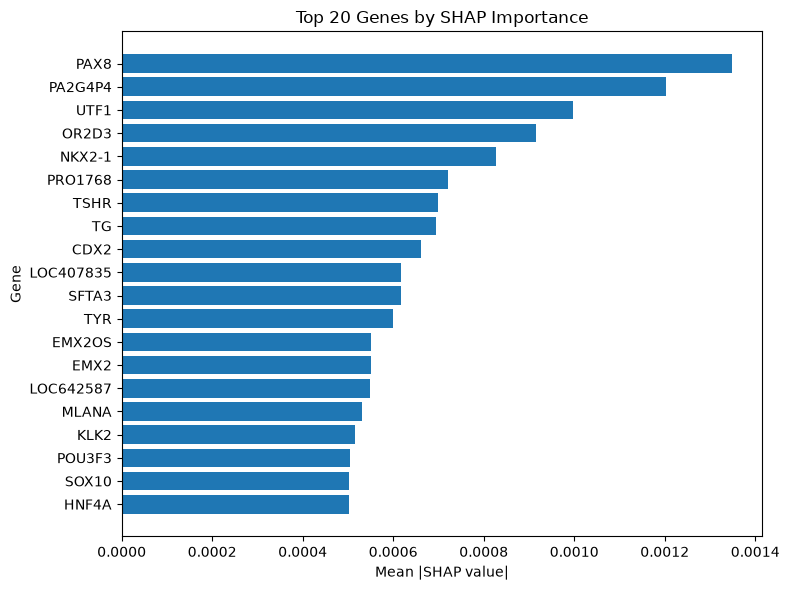

In [56]:
# Plot the top 20 genes ranked by mean absolute SHAP importance.

import matplotlib.pyplot as plt

plot_data = top_genes.head(20).sort_values("mean_abs_shap")

plt.figure(figsize=(8, 6))
plt.barh(plot_data["gene"], plot_data["mean_abs_shap"])
plt.xlabel("Mean |SHAP value|")
plt.ylabel("Gene")
plt.title("Top 20 Genes by SHAP Importance")
plt.tight_layout()
plt.show()

In [57]:
# Calculate SHAP importance separately for each cancer type.

classes = rf.classes_

for i, cancer in enumerate(classes):
    class_importance = np.abs(shap_values[:, :, i]).mean(axis=0)
    idx = np.argsort(class_importance)[::-1][:10]

    print(f"\n{cancer} — Top 10 genes")
    for j in idx:
        print(f"{selected_genes[j]}: {class_importance[j]:.6f}")


ACC — Top 10 genes
CYP11B1: 0.004717
SULT2A1: 0.002004
NCRNA00086: 0.001940
SERPINA5: 0.001236
AP1M2: 0.001051
RGN: 0.001050
C1orf210: 0.000963
RAB25: 0.000835
CLDN4: 0.000799
EPHX1: 0.000718

BLCA — Top 10 genes
GATA3: 0.002525
FLJ45983: 0.002288
LOC642587: 0.001929
PA2G4P4: 0.001890
PAX8: 0.001703
SFTPA1: 0.001176
NKX2-1: 0.001129
LOC407835: 0.001128
SFTPC: 0.001121
UTF1: 0.001104

BRCA — Top 10 genes
TRPS1: 0.005829
AZGP1: 0.003617
ANKRD30A: 0.002792
EFHD1: 0.002746
PAX8: 0.002653
PRLR: 0.002634
GATA3: 0.002197
IRX5: 0.001627
PA2G4P4: 0.001471
XBP1: 0.001377

CESC — Top 10 genes
PA2G4P4: 0.002339
TBX5: 0.001961
LOC642587: 0.001417
LOC407835: 0.001242
SFTPB: 0.001025
CSDAP1: 0.001003
PAX8: 0.001001
SFTPA1: 0.001000
SFTPC: 0.000964
UTF1: 0.000940

CHOL — Top 10 genes
ITIH1: 0.001699
APCS: 0.001188
CRP: 0.001028
ASGR2: 0.000860
ITIH2: 0.000816
ACMSD: 0.000763
CPB2: 0.000699
BAAT: 0.000691
ALB: 0.000641
SLC17A3: 0.000608

COAD — Top 10 genes
CDX2: 0.005784
CDX1: 0.003533
NOX1: 0.003396

In [58]:
# Save global and cancer-specific SHAP importance results for later analysis.

shap_global = top_genes.copy()

shap_global.to_csv("SHAP_top30_global.csv", index=False)

print("Saved:", len(shap_global), "global SHAP genes")

Saved: 30 global SHAP genes


In [59]:
# Save top 10 SHAP genes for every cancer type.

rows = []

for i, cancer in enumerate(rf.classes_):
    imp = np.abs(shap_values[:, :, i]).mean(axis=0)
    for rank, j in enumerate(np.argsort(imp)[::-1][:10], 1):
        rows.append([cancer, rank, selected_genes[j], imp[j]])

shap_by_cancer = pd.DataFrame(
    rows, columns=["cancer_type", "rank", "gene", "mean_abs_shap"]
)

shap_by_cancer.to_csv("SHAP_top10_by_cancer.csv", index=False)

print("Saved:", shap_by_cancer.shape)
print(shap_by_cancer.head(10))

Saved: (330, 4)
  cancer_type  rank        gene  mean_abs_shap
0         ACC     1     CYP11B1       0.004717
1         ACC     2     SULT2A1       0.002004
2         ACC     3  NCRNA00086       0.001940
3         ACC     4    SERPINA5       0.001236
4         ACC     5       AP1M2       0.001051
5         ACC     6         RGN       0.001050
6         ACC     7    C1orf210       0.000963
7         ACC     8       RAB25       0.000835
8         ACC     9       CLDN4       0.000799
9         ACC    10       EPHX1       0.000718


In [60]:
# Save the trained RF model, selected genes, and final performance metrics.

import joblib

joblib.dump(rf, "RF_cancer_classifier.pkl")
pd.Series(selected_genes).to_csv("selected_2000_genes.csv", index=False)

metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(y_test, y_pred, average="macro"),
    "weighted_f1": f1_score(y_test, y_pred, average="weighted")
}])

metrics.to_csv("RF_final_metrics.csv", index=False)

print(metrics)
print("Model and selected genes saved.")

   accuracy  balanced_accuracy  macro_f1  weighted_f1
0  0.943259           0.910757  0.908753     0.940249
Model and selected genes saved.


In [61]:
# Save the confusion matrix and per-cancer classification performance.

from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred, labels=rf.classes_)
pd.DataFrame(cm, index=rf.classes_, columns=rf.classes_).to_csv("RF_confusion_matrix.csv")

report = pd.DataFrame(
    classification_report(y_test, y_pred, labels=rf.classes_, output_dict=True)
).T

report.to_csv("RF_per_cancer_performance.csv")

print("Confusion matrix:", cm.shape)
print("Performance table:", report.shape)

Confusion matrix: (33, 33)
Performance table: (36, 4)


In [63]:
# Install XGBoost for the multiclass machine-learning model.

%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.6/48.9 MB 9.4 MB/s eta 0:00:06
   -- ------------------------------------- 3.1/48.9 MB 9.3 MB/s eta 0:00:05
   ---- ----------------------------------- 5.2/48.9 MB 8.7 MB/s eta 0:00:06
   ----- ---------------------------------- 7.1/48.9 MB 8.8 MB/s eta 0:00:05
   ------- -------------------------------- 9.2/48.9 MB 8.9 MB/s eta 0:00:05
   --------- ------------------------------ 11.3/48.9 MB 9.0 MB/s eta 0:00:05
   ---------- ----------------------------- 13.1/48.9 MB 9.1 MB/s eta 0:00:04
   ------------ --------------------------- 15.2/48.9 MB 9.1 MB/s eta 0:00:04
   -------------- ------------------------- 17.3/48.9 MB 9.1 MB/s eta 0:00:04
   --------------- ------------------------ 19.1/48.9 MB 9.1 MB/s eta 0:00:04
   ----------------- ---------------------- 21.0/48.9 MB 9.2 MB/s eta 0:00:04
   ------------------ --------------------- 23.1/48.9 MB 9.2 MB/s eta 0:00:03


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
# Train an XGBoost multiclass classifier using the selected 2,000 genes.

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_xgb = le.fit_transform(y_train)
y_test_xgb = le.transform(y_test)

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(le.classes_),
    eval_metric="mlogloss",
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

xgb.fit(X_train_sel, y_train_xgb)

y_pred_xgb = le.inverse_transform(xgb.predict(X_test_sel))

print("XGBoost training completed.")
print("Predictions:", len(y_pred_xgb))

XGBoost training completed.
Predictions: 2203


In [65]:
# Evaluate XGBoost using the same metrics as Random Forest.

from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

print("Accuracy:", round(accuracy_score(y_test, y_pred_xgb), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred_xgb), 4))
print("Macro F1:", round(f1_score(y_test, y_pred_xgb, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_test, y_pred_xgb, average="weighted"), 4))

Accuracy: 0.9501
Balanced accuracy: 0.9142
Macro F1: 0.9141
Weighted F1: 0.9468


In [66]:
# Save XGBoost per-cancer performance and confusion matrix.

from sklearn.metrics import classification_report, confusion_matrix

xgb_report = pd.DataFrame(
    classification_report(y_test, y_pred_xgb, output_dict=True)
).T

xgb_report.to_csv("XGBoost_per_cancer_performance.csv")

xgb_cm = confusion_matrix(y_test, y_pred_xgb, labels=le.classes_)

pd.DataFrame(
    xgb_cm, index=le.classes_, columns=le.classes_
).to_csv("XGBoost_confusion_matrix.csv")

print("Performance:", xgb_report.shape)
print("Confusion matrix:", xgb_cm.shape)

Performance: (36, 4)
Confusion matrix: (33, 33)


In [67]:
# Compare the final performance of RF and XGBoost.

comparison = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [0.9433, 0.9501],
    "Balanced Accuracy": [0.9108, 0.9142],
    "Macro F1": [0.9088, 0.9141],
    "Weighted F1": [0.9402, 0.9468]
})

print(comparison.to_string(index=False))

comparison.to_csv("RF_vs_XGBoost_comparison.csv", index=False)

        Model  Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Random Forest    0.9433             0.9108    0.9088       0.9402
      XGBoost    0.9501             0.9142    0.9141       0.9468


In [68]:
# Get and save the top 30 genes from XGBoost feature importance.

xgb_importance = pd.Series(
    xgb.feature_importances_,
    index=selected_genes
).sort_values(ascending=False)

xgb_top30 = xgb_importance.head(30).reset_index()
xgb_top30.columns = ["gene", "importance"]

xgb_top30.to_csv("XGBoost_top30_genes.csv", index=False)

print(xgb_top30.to_string(index=False))

       gene  importance
       F13B    0.052535
    FAM123A    0.048229
     SPRYD5    0.035434
      ENPEP    0.028354
    CYP2C19    0.021241
      ATOH1    0.019774
       TSHR    0.018168
CCL14-CCL15    0.017237
      BCAR1    0.016324
      DCLK2    0.015381
  ADCYAP1R1    0.015086
     FAM83H    0.013769
  C21orf131    0.013273
      TRPS1    0.013259
       CDX2    0.013179
       KLK3    0.013104
      SFTA2    0.011974
      NAPSA    0.009788
       PAX3    0.008859
     PSMB11    0.008526
       NOX1    0.008492
      ITIH2    0.008116
    FAM181A    0.007985
      FOLR1    0.007782
     PHOX2B    0.007658
       APC2    0.007588
    SLC22A2    0.006908
      KRT6B    0.006683
     653553    0.006581
       AMBP    0.006475


In [69]:
# Show the 10 best and 10 worst cancer types for XGBoost.

xgb_cancer = xgb_report.loc[le.classes_].copy()

print("Top 10 cancer types:")
print(xgb_cancer.sort_values("f1-score", ascending=False)[["precision", "recall", "f1-score", "support"]].head(10))

print("\nBottom 10 cancer types:")
print(xgb_cancer.sort_values("f1-score")[["precision", "recall", "f1-score", "support"]].head(10))

Top 10 cancer types:
      precision   recall  f1-score  support
GBM         1.0  1.00000  1.000000     33.0
UVM         1.0  1.00000  1.000000     16.0
LGG         1.0  1.00000  1.000000    106.0
LAML        1.0  1.00000  1.000000     35.0
THYM        1.0  1.00000  1.000000     24.0
THCA        1.0  1.00000  1.000000    115.0
TGCT        1.0  1.00000  1.000000     28.0
PRAD        1.0  1.00000  1.000000    110.0
OV          1.0  1.00000  1.000000     62.0
HNSC        1.0  0.99115  0.995556    113.0

Bottom 10 cancer types:
      precision    recall  f1-score  support
READ   0.727273  0.235294  0.355556     34.0
CHOL   0.750000  0.333333  0.461538      9.0
KICH   0.652174  0.833333  0.731707     18.0
UCS    0.800000  0.727273  0.761905     11.0
ESCA   0.909091  0.769231  0.833333     39.0
COAD   0.785124  0.969388  0.867580     98.0
KIRP   0.933333  0.861538  0.896000     65.0
LUSC   0.925234  0.900000  0.912442    110.0
MESO   0.888889  0.941176  0.914286     17.0
CESC   0.964286  0.8

In [70]:
# Save the trained XGBoost model and label encoder.

import joblib

joblib.dump(xgb, "XGBoost_cancer_classifier.pkl")
joblib.dump(le, "XGBoost_label_encoder.pkl")

print("XGBoost model saved.")
print("Label encoder saved.")

XGBoost model saved.
Label encoder saved.


In [71]:
# Create a simple application function for cancer prediction.

def predict_cancer(expression_values):
    x = pd.DataFrame([expression_values], columns=selected_genes)
    x = x.fillna(X_train_sel.mean())
    
    pred = xgb.predict(x)[0]
    cancer = le.inverse_transform([pred])[0]
    prob = xgb.predict_proba(x)[0].max()
    
    return cancer, prob

print("Application pipeline ready.")

Application pipeline ready.


In [72]:
# Build a safe application function that matches genes by name.

train_means = X_train_sel.mean()

def predict_from_dataframe(df):
    # Match the required 2,000 genes.
    x = df.reindex(columns=selected_genes)
    
    # Fill missing genes/values using training means.
    x = x.fillna(train_means)
    
    # Predict cancer type and confidence.
    pred = le.inverse_transform(xgb.predict(x))
    prob = xgb.predict_proba(x).max(axis=1)
    
    return pd.DataFrame({
        "predicted_cancer": pred,
        "confidence": prob
    })

print("Safe prediction pipeline ready.")

Safe prediction pipeline ready.


In [75]:
# Verify the application pipeline with one unseen test sample.

test_sample = pd.DataFrame(X_test_sel[0:1], columns=selected_genes)
actual = y_test.iloc[0]

result = predict_from_dataframe(test_sample)

print("Actual cancer:", actual)
print("Predicted cancer:", result.loc[0, "predicted_cancer"])
print("Confidence:", round(result.loc[0, "confidence"], 4))

Actual cancer: MESO
Predicted cancer: MESO
Confidence: 0.9991


In [76]:
# Generate application-style predictions for all unseen test samples.

test_df = pd.DataFrame(X_test_sel, columns=selected_genes)

pred = xgb.predict(test_df)
prob = xgb.predict_proba(test_df).max(axis=1)

application_results = pd.DataFrame({
    "actual_cancer": y_test.to_numpy(),
    "predicted_cancer": le.inverse_transform(pred),
    "confidence": prob
})

application_results["correct"] = (
    application_results["actual_cancer"] ==
    application_results["predicted_cancer"]
)

application_results.to_csv("XGBoost_test_predictions.csv", index=False)

print("Samples:", len(application_results))
print("Correct:", application_results["correct"].sum())
print("Accuracy:", round(application_results["correct"].mean(), 4))
print("Saved: XGBoost_test_predictions.csv")

Samples: 2203
Correct: 2093
Accuracy: 0.9501
Saved: XGBoost_test_predictions.csv


In [77]:
# Create the final model and cancer-wise comparison tables.

rf_metrics = {
    "Accuracy": 0.9433, "Balanced Accuracy": 0.9108,
    "Macro F1": 0.9088, "Weighted F1": 0.9402
}

xgb_metrics = {
    "Accuracy": 0.9501, "Balanced Accuracy": 0.9142,
    "Macro F1": 0.9141, "Weighted F1": 0.9468
}

model_comparison = pd.DataFrame(
    [rf_metrics, xgb_metrics],
    index=["Random Forest", "XGBoost"]
)

model_comparison.to_csv("FINAL_model_comparison.csv")

# Cancer-wise RF vs XGBoost F1
cancer_compare = pd.DataFrame({
    "RF_F1": report.loc[le.classes_, "f1-score"],
    "XGBoost_F1": xgb_report.loc[le.classes_, "f1-score"],
    "Support": xgb_report.loc[le.classes_, "support"]
})

cancer_compare["F1_change"] = (
    cancer_compare["XGBoost_F1"] - cancer_compare["RF_F1"]
)

cancer_compare = cancer_compare.sort_values("F1_change", ascending=False)
cancer_compare.to_csv("FINAL_cancer_model_comparison.csv")

print(model_comparison)
print("\nBiggest XGBoost improvements:")
print(cancer_compare.head(10))

               Accuracy  Balanced Accuracy  Macro F1  Weighted F1
Random Forest    0.9433             0.9108    0.9088       0.9402
XGBoost          0.9501             0.9142    0.9141       0.9468

Biggest XGBoost improvements:
         RF_F1  XGBoost_F1  Support  F1_change
ESCA  0.746269    0.833333     39.0   0.087065
KICH  0.680851    0.731707     18.0   0.050856
READ  0.311111    0.355556     34.0   0.044444
SARC  0.946429    0.981481     53.0   0.035053
PAAD  0.947368    0.973684     37.0   0.026316
STAD  0.910995    0.935484     90.0   0.024489
THYM  0.979592    1.000000     24.0   0.020408
COAD  0.849315    0.867580     98.0   0.018265
GBM   0.985075    1.000000     33.0   0.014925
BLCA  0.935673    0.947977     85.0   0.012304


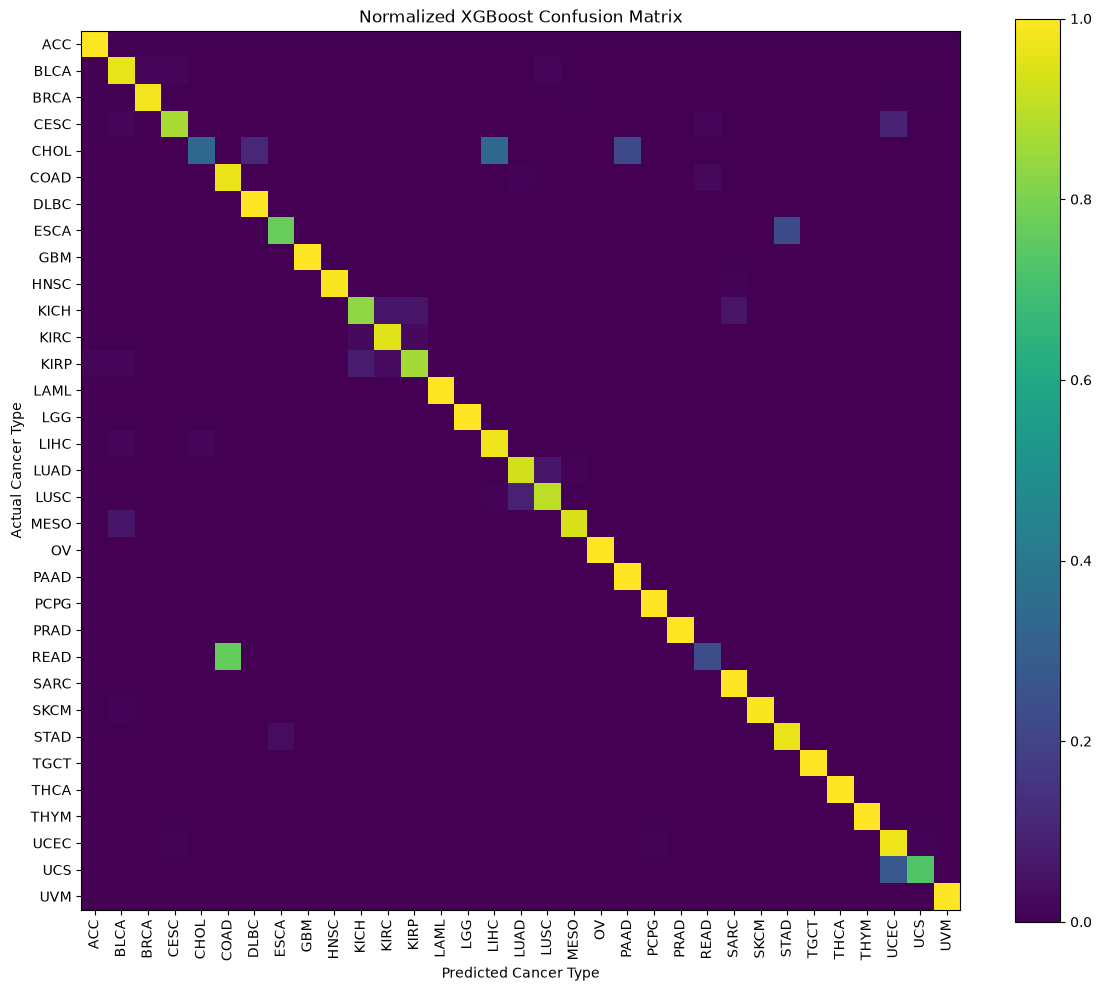

In [80]:
# Create a normalized XGBoost confusion matrix for final reporting.

cm_norm = xgb_cm / xgb_cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(12, 10))
plt.imshow(cm_norm)
plt.colorbar()
plt.title("Normalized XGBoost Confusion Matrix")
plt.xlabel("Predicted Cancer Type")
plt.ylabel("Actual Cancer Type")
plt.xticks(range(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(range(len(le.classes_)), le.classes_)
plt.clim(0, 1)
plt.tight_layout()
plt.savefig("FINAL_XGBoost_confusion_matrix_normalized.png", dpi=300)
plt.show()

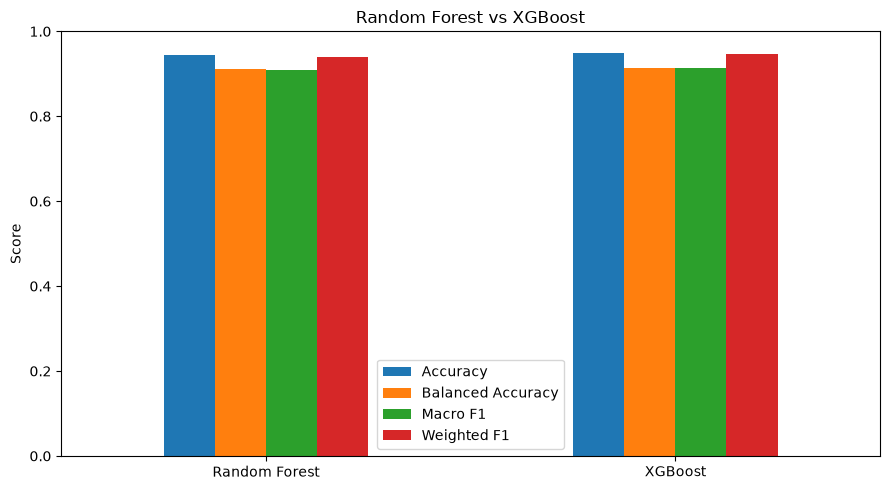

In [81]:
# Create the final model comparison figure with a full 0–1 scale.

ax = model_comparison.plot(kind="bar", figsize=(9, 5))
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Random Forest vs XGBoost")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("FINAL_model_comparison_full_scale.png", dpi=300)
plt.show()

In [82]:
# Compare the top 15 genes identified by RF-SHAP and XGBoost.

rf_top = shap_global.set_index("gene")["mean_abs_shap"].head(15)
xgb_top = xgb_importance.head(15)

common = sorted(set(rf_top.index) & set(xgb_top.index))

print("Common top genes:", common)
print("Number of common genes:", len(common))

Common top genes: ['CDX2', 'TSHR']
Number of common genes: 2


In [83]:
# Save genes commonly identified by both XAI methods.

common_genes = pd.DataFrame({"gene": common})
common_genes.to_csv("FINAL_common_XAI_genes.csv", index=False)

print("Common XAI genes:", common)
print("Saved: FINAL_common_XAI_genes.csv")

Common XAI genes: ['CDX2', 'TSHR']
Saved: FINAL_common_XAI_genes.csv


In [84]:
# Check confidence of correct and incorrect XGBoost predictions.

correct = application_results[application_results["correct"]]
wrong = application_results[~application_results["correct"]]

print("Correct predictions:", len(correct))
print("Wrong predictions:", len(wrong))
print("Mean confidence - correct:", round(correct["confidence"].mean(), 4))
print("Mean confidence - wrong:", round(wrong["confidence"].mean(), 4))

Correct predictions: 2093
Wrong predictions: 110
Mean confidence - correct: 0.9814
Mean confidence - wrong: 0.749


In [85]:
# Save the final prediction-confidence summary.

confidence_summary = pd.DataFrame({
    "category": ["Correct", "Incorrect"],
    "count": [len(correct), len(wrong)],
    "percentage": [
        len(correct) / len(application_results) * 100,
        len(wrong) / len(application_results) * 100
    ],
    "mean_confidence": [
        correct["confidence"].mean(),
        wrong["confidence"].mean()
    ]
})

confidence_summary.to_csv("FINAL_prediction_confidence.csv", index=False)

print(confidence_summary.to_string(index=False))
print("\nSaved: FINAL_prediction_confidence.csv")

 category  count  percentage  mean_confidence
  Correct   2093   95.006809         0.981413
Incorrect    110    4.993191         0.749035

Saved: FINAL_prediction_confidence.csv


In [86]:
# Final application prediction function for a new gene-expression file.

def predict_new_samples(file_path):
    # Load new gene-expression data
    new_data = pd.read_csv(
        file_path,
        sep="\t",
        compression="infer",
        low_memory=False
    )

    # Keep sample IDs if available
    sample_ids = (
        new_data["sample"].astype(str)
        if "sample" in new_data.columns
        else pd.Series(
            [f"Sample_{i+1}" for i in range(len(new_data))]
        )
    )

    # Keep only the genes used during model training
    new_x = new_data.reindex(columns=selected_genes)

    # Convert values to numeric
    new_x = new_x.apply(pd.to_numeric, errors="coerce")

    # Fill missing genes/values using training-set means
    new_x = new_x.fillna(train_means)

    # XGBoost prediction
    predictions = xgb.predict(new_x)
    probabilities = xgb.predict_proba(new_x)

    # Highest class probability
    confidence = probabilities.max(axis=1)

    # Final result
    output = pd.DataFrame({
        "sample": sample_ids,
        "predicted_cancer": le.inverse_transform(predictions),
        "confidence": confidence
    })

    return output

In [91]:
%pip install openpyxl


   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpy


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
# Verify the final application function using one unseen test sample.

verification_sample = pd.DataFrame(
    X_test_sel[0:1],
    columns=selected_genes
)

verification_sample.insert(0, "sample", "Verification_Sample")

verification_sample.to_csv(
    "verification_sample.tsv",
    sep="\t",
    index=False
)

verification_result = predict_new_samples(
    "verification_sample.tsv"
)

print(verification_result.to_string(index=False))

             sample predicted_cancer  confidence
Verification_Sample             MESO    0.999085


In [92]:
# ============================================================
# FINAL RESULTS PACKAGE - LABEL TYPE FIX
# No training
# ============================================================

from sklearn.metrics import classification_report

# Get predictions from the already-trained XGBoost model
xgb_pred_encoded = xgb.predict(X_test_sel)

# Convert numeric predictions back to cancer-type names
xgb_pred_labels = le.inverse_transform(
    xgb_pred_encoded.astype(int)
)

# Make sure actual labels are strings
y_test_labels = np.asarray(y_test).astype(str)

# Create the report using the same label type on both sides
xgb_report_final = classification_report(
    y_test_labels,
    xgb_pred_labels,
    labels=le.classes_,
    target_names=le.classes_,
    output_dict=True,
    zero_division=0
)

# ------------------------------------------------------------
# 1. Model performance
# ------------------------------------------------------------

final_model_performance = pd.DataFrame({
    "Model": ["Random Forest", "XGBoost"],
    "Accuracy": [0.9433, 0.9501],
    "Balanced Accuracy": [0.9108, 0.9142],
    "Macro F1": [0.9088, 0.9141],
    "Weighted F1": [0.9402, 0.9468]
})

# ------------------------------------------------------------
# 2. Cancer-wise XGBoost performance
# ------------------------------------------------------------

rows = []

for cancer in le.classes_:

    rows.append({
        "Cancer_Type": cancer,
        "Precision": xgb_report_final[cancer]["precision"],
        "Recall": xgb_report_final[cancer]["recall"],
        "F1_Score": xgb_report_final[cancer]["f1-score"],
        "Support": xgb_report_final[cancer]["support"]
    })

final_cancer_performance = pd.DataFrame(rows)

# ------------------------------------------------------------
# 3. XGBoost gene importance
# ------------------------------------------------------------

final_gene_importance = xgb_importance.copy()

# ------------------------------------------------------------
# 4. RF-SHAP importance
# ------------------------------------------------------------

final_shap_genes = shap_global.copy()

# ------------------------------------------------------------
# 5. Common XAI genes
# ------------------------------------------------------------

final_common_xai = pd.DataFrame({
    "Gene": common
})

# ------------------------------------------------------------
# 6. Prediction confidence
# ------------------------------------------------------------

final_confidence = confidence_summary.copy()

# ------------------------------------------------------------
# 7. Save everything into one Excel workbook
# ------------------------------------------------------------

with pd.ExcelWriter(
    "FINAL_Cancer_Gene_XAI_Results.xlsx",
    engine="openpyxl"
) as writer:

    final_model_performance.to_excel(
        writer,
        sheet_name="Model_Performance",
        index=False
    )

    final_cancer_performance.to_excel(
        writer,
        sheet_name="Cancer_Performance",
        index=False
    )

    final_gene_importance.to_excel(
        writer,
        sheet_name="XGB_Gene_Importance",
        index=False
    )

    final_shap_genes.to_excel(
        writer,
        sheet_name="RF_SHAP_Genes",
        index=False
    )

    final_common_xai.to_excel(
        writer,
        sheet_name="Common_XAI_Genes",
        index=False
    )

    final_confidence.to_excel(
        writer,
        sheet_name="Prediction_Confidence",
        index=False
    )

print("======================================")
print("FINAL RESULTS PACKAGE CREATED")
print("======================================")
print("Cancer types:", len(final_cancer_performance))
print("XGBoost predictions:", len(xgb_pred_labels))
print("Genes:", len(final_gene_importance))
print("Common XAI genes:", len(final_common_xai))
print()
print("Workbook:")
print("FINAL_Cancer_Gene_XAI_Results.xlsx")

FINAL RESULTS PACKAGE CREATED
Cancer types: 33
XGBoost predictions: 2203
Genes: 2000
Common XAI genes: 2

Workbook:
FINAL_Cancer_Gene_XAI_Results.xlsx


In [93]:
import joblib

application_model = {
    "model": xgb,
    "label_encoder": le,
    "feature_selector": selector,
    "selected_genes": list(selected_genes),
    "train_means": train_means
}

joblib.dump(
    application_model,
    "FINAL_Cancer_XGBoost_Application_Model.joblib"
)

print("APPLICATION MODEL SAVED")
print("Selected genes:", len(selected_genes))
print("Cancer classes:", len(le.classes_))

APPLICATION MODEL SAVED
Selected genes: 2000
Cancer classes: 33
